# Home Work : Regression (รวม Part 1 + Part 2)


| ข้อ | หัวข้อ                                                 |
|-----|--------------------------------------------------------|
| 1   | Plot ข้อมูลการเคลื่อนที่แบบวิถีโค้ง                    |
| 2   | Solve by Linear Regression                             |
| 3   | Solve by Polynomial Regression                         |
| 4   | ใช้ $L_1$ optimization สำหรับ Noise Filter             |
| 5   | **เทียบ $L_1$ กับ $L_2$                                |

**วิธีทำ:** แต่ละข้อให้ลองคิดด้วยมือก่อนว่าคำตอบควรออกมาหน้าตาแบบไหน
แล้วค่อยเขียนโค้ดตรวจว่าตรงกันไหม

**หมายเหตุ**`# TODO` คือส่วนที่ต้องเติม

In [ ]:
# ถ้ายังไม่ได้ติดตั้ง cvxpy ให้ uncomment บรรทัดล่างแล้วรัน
#!pip install cvxpy

: 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    import cvxpy as cvx
    HAS_CVXPY = True
except ImportError:
    HAS_CVXPY = False

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
np.set_printoptions(precision=4, suppress=True)

print("มี cvxpy หรือไม่ :", HAS_CVXPY)

มี cvxpy หรือไม่ : True


---
# Part 1 : การเคลื่อนที่แบบวิถีโค้ง (Projectile Motion)

## การเคลื่อนที่แบบวิถีโค้งโดยไม่มีแรงต้านอากาศ

ความเร็วต้น $v_0$ สามารถแยกออกเป็นองค์ประกอบแนวนอน ($v_{x_0}$) และแนวดิ่ง ($v_{y_0}$) โดยอ้างอิงจากมุมยิง $ \theta $ ได้ดังนี้:

$$
v_{x_0} = v_0 \cos(\theta) \\
v_{y_0} = v_0 \sin(\theta)
$$

เมื่อไม่มีแรงต้านอากาศ การเคลื่อนที่จะได้รับอิทธิพลจากแรงโน้มถ่วงเพียงอย่างเดียว
ดังนั้นสมการการกระจัดในแนวนอน $x$ และแนวดิ่ง $y$ คือ:

$$
x = v_{x_0} t = v_0 \cos(\theta) t \\
y = v_{y_0} t - \tfrac{1}{2} g t^2 = v_0 \sin(\theta) t - \tfrac{1}{2} g t^2
$$

## ข้อมูลที่ใช้


- `01_Projectile_without_Resistance_data.csv`  ข้อมูลที่วัดได้ (มี noise)
- `01_Projectile_without_Resistance_true_data.csv`  เส้นทางจริง (ไว้ใช้ตรวจคำตอบตอนท้าย)

<center>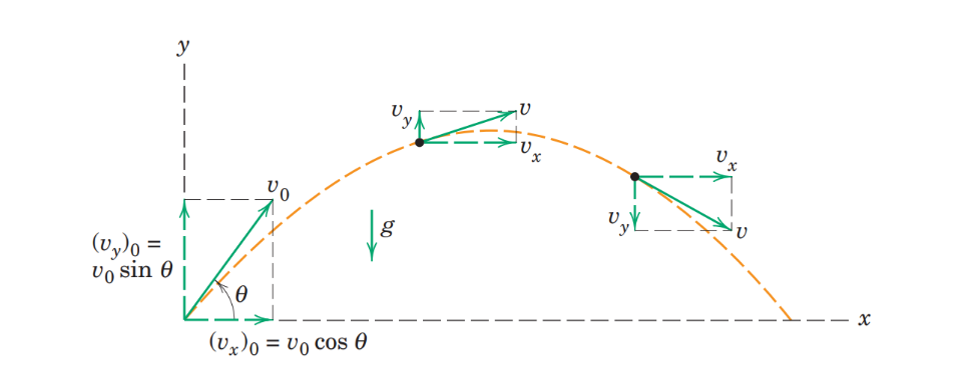</center>

In [3]:
# ---------- โหลดข้อมูล ----------
# ถ้ารันบน Colab : mount Drive ก่อน แล้วแก้ DATA_DIR ให้ชี้ไปที่โฟลเดอร์ที่เก็บ csv
#     from google.colab import drive
#     drive.mount('/content/drive')
#     DATA_DIR = "/content/drive/MyDrive/ML/ML_data/"
# ด้านบนเป็นตัวอย่างในการ mount drive ของ google drive แนะนำให้ลากไฟล์เอา tab file
DATA_DIR = ""        # ว่างไว้ = ไฟล์ csv อยู่โฟลเดอร์เดียวกับ notebook

data = np.loadtxt(DATA_DIR + "01_Projectile_without_Resistance_data.csv",
                  delimiter=",", skiprows=1)
true = np.loadtxt(DATA_DIR + "01_Projectile_without_Resistance_true_data.csv",
                  delimiter=",", skiprows=1)

t, x, y = data[:, 0], data[:, 1], data[:, 2]              # ข้อมูลที่วัดได้ (มี noise)
t_true, x_true, y_true = true[:, 0], true[:, 1], true[:, 2]   # เส้นทางจริง

print(f"ข้อมูลที่วัดได้ : {data.shape[0]} จุด   ช่วงเวลา {t.min():.2f} - {t.max():.2f} วินาที")
print(f"เส้นทางจริง    : {true.shape[0]} จุด   ช่วงเวลา {t_true.min():.2f} - {t_true.max():.2f} วินาที")
print(data.shape)

ข้อมูลที่วัดได้ : 25 จุด   ช่วงเวลา 0.55 - 3.22 วินาที
เส้นทางจริง    : 100 จุด   ช่วงเวลา 0.00 - 4.32 วินาที
(25, 3)


---
## ข้อ 1 : plot data

ก่อนจะ fit อะไรลงไป ควร **ดูข้อมูลก่อนเสมอ** เพื่อจะได้รู้ว่าควรใช้โมเดลหน้าตาแบบไหน

**โจทย์:** พล็อต 2 แผง

- แผงซ้าย : $x$ เทียบกับ $t$
- แผงขวา : $y$ เทียบกับ $t$

ในแต่ละแผงให้ใส่ทั้งจุดข้อมูลที่วัดได้ (scatter) และเส้นทางจริง (เส้นประ)
แล้วตอบว่าแต่ละแผงควรใช้พหุนามดีกรีเท่าไรจึงจะเหมาะสม

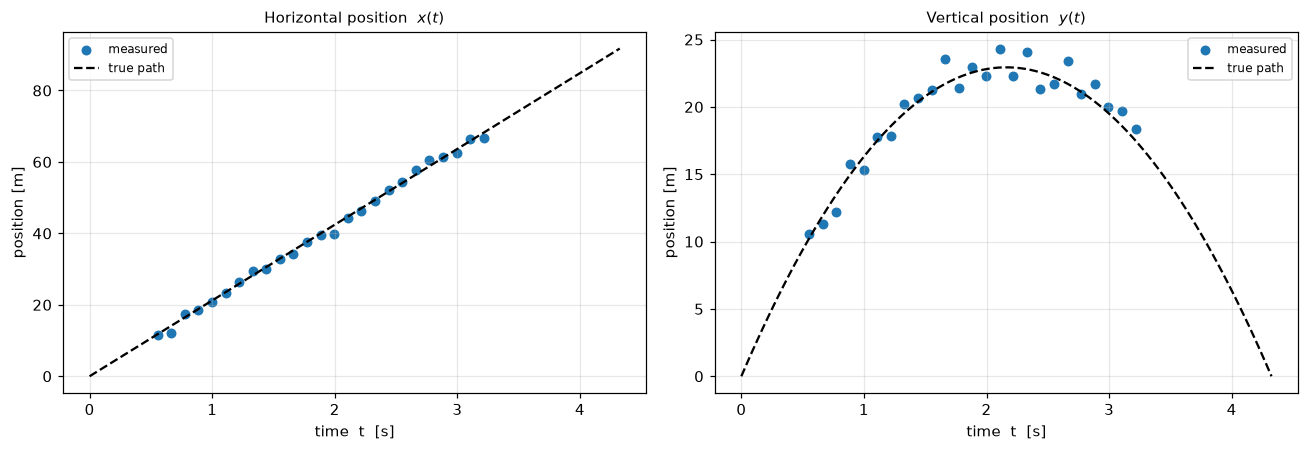

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# TODO 1: ในด้านซ้าย (axes[0]) พล็อตจุดข้อมูล x เทียบกับ t ด้วย scatter
#         และในด้านขวา (axes[1]) พล็อตจุดข้อมูล y เทียบกับ t ด้วย scatter
#         คำใบ้: axes[0].scatter(t, x, s=30, label="measured")
axes[0].scatter(t, x, s=30, label="measured")
axes[1].scatter(t, y, s=30, label="measured")

axes[0].plot(t_true, x_true, "k--", lw=1.5, label="true path")
axes[1].plot(t_true, y_true, "k--", lw=1.5, label="true path")
axes[0].set_title("Horizontal position  $x(t)$", fontsize=10)
axes[1].set_title("Vertical position  $y(t)$", fontsize=10)
for ax in axes:
    ax.set_xlabel("time  t  [s]"); ax.set_ylabel("position [m]"); ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

> **เขียนตอบข้อ 1 ตรงนี้** — จากกราฟทั้งสอง ควรใช้สมการ order เท่าไร เพราะอะไร

**ตอบ**

| แผง | Order ที่เหมาะสม | เหตุผล |
|---|:---:|---|
| $x(t)$ | **1** | จุดข้อมูลเรียงตัวเป็นเส้นตรง |
| $y(t)$ | **2** | จุดข้อมูลเรียงตัวเป็นพาราโบลา |

---
## ข้อ 2 : Linear Regression

เราจะ fit เส้นตรง $\hat{y} = w_0 + w_1 t$ เข้ากับข้อมูล $y$

**เขียนให้อยู่ในรูปเมทริกซ์**  ถ้ามีข้อมูล $m$ จุด จะได้

$$\underbrace{\begin{bmatrix} 1 & t_1 \\ 1 & t_2 \\ \vdots & \vdots \\ 1 & t_m \end{bmatrix}}_{A}
\underbrace{\begin{bmatrix} w_0 \\ w_1 \end{bmatrix}}_{w}
\;\approx\;
\underbrace{\begin{bmatrix} y_1 \\ y_2 \\ \vdots \\ y_m \end{bmatrix}}_{b}$$

สมการนี้ **ไม่มีคำตอบ** เพราะมีสมการ $m$ อัน แต่มีตัวแปรแค่ 2 ตัว (over-determined)
เราจึงหา $w$ ที่ทำให้ $\lVert Aw - b \rVert_2$ น้อยที่สุดแทน

$$w^\star = \arg\min_w \lVert Aw - b\rVert_2^2$$

**โจทย์:** สร้างเมทริกซ์ $A$ แล้วหา $w^\star$ สามารถประยุกต์ใช้ least squares, Gradient Descent หรือ CVXPY

(25, 2) (2,)
ค่า w1 จาก numpy = [13.7519  3.1209]
ค่า w1 จาก cvxpy = [13.7519  3.1209]
โมเดลเส้นตรง : y = +13.752 +3.121 t
RMSE บนข้อมูลที่วัดได้ = 2.9057


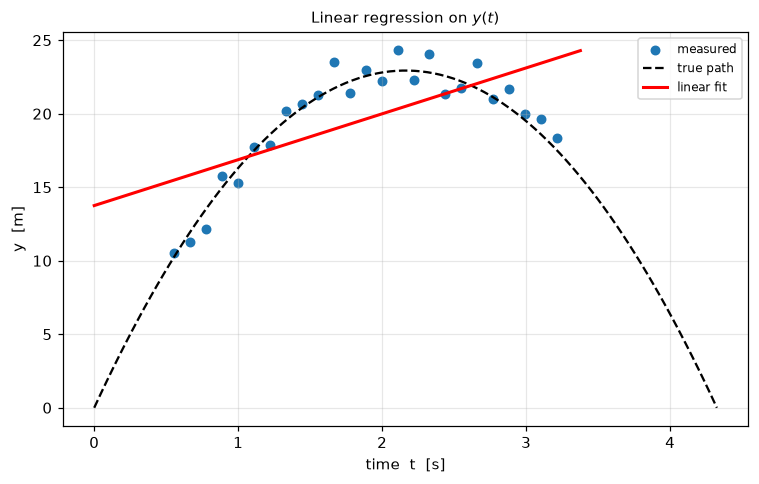

In [ ]:
# TODO 2: สร้างเมทริกซ์ A1 (ขนาด m x 2 : คอลัมน์แรกเป็น 1 ทั้งหมด คอลัมน์สองเป็น t)

A1 = np.column_stack((np.ones_like(t), t))
w1 = np.linalg.lstsq(A1, y, rcond=None)[0]

# เช็คขนาดของ A1 และ w1 ว่าถูกต้องหรือไม่
print(A1.shape, w1.shape)

#ลองวิธี numpy  เพื่อแก้ปัญหา least squares
result = np.linalg.lstsq(A1, y, rcond=None)
print("ค่า w1 จาก numpy =", result[0])

# ลองวิธี cvxpy  เพื่อแก้ปัญหา least squares
z = cvx.Variable(2)
objective = cvx.Minimize(cvx.sum_squares(A1 @ z - y))
prob = cvx.Problem(objective)
prob.solve()
print("ค่า w1 จาก cvxpy =", z.value)


# -------------------- สามารถแก้ได้ตามอิสระ -------- #
rmse1 = np.sqrt(np.mean((A1 @ w1 - y) ** 2))
print(f"โมเดลเส้นตรง : y = {w1[0]:+.3f} {w1[1]:+.3f} t")
print(f"RMSE บนข้อมูลที่วัดได้ = {rmse1:.4f}")

ts = np.linspace(0, t.max() * 1.05, 200)
plt.figure(figsize=(7, 4.5))
plt.scatter(t, y, s=30, label="measured")
plt.plot(t_true, y_true, "k--", lw=1.5, label="true path")
plt.plot(ts, w1[0] + w1[1] * ts, "r-", lw=2, label="linear fit")
plt.xlabel("time  t  [s]"); plt.ylabel("y  [m]"); plt.legend(fontsize=8)
plt.title("Linear regression on $y(t)$", fontsize=10)
plt.tight_layout()
plt.show()

---
## ข้อ 3 : Polynomial Regression (กำลังสอง)

จากข้อ 2 จะเห็นว่าเส้นตรงอธิบายข้อมูลได้ไม่ดี เพราะตามทฤษฎีแล้ว $y(t)$ เป็น**พาราโบลา**
เราจึงเปลี่ยนโมเดลเป็น

$$\hat{y} = w_0 + w_1 t + w_2 t^2$$

**จุดสำคัญ:** โมเดลนี้ยังเป็น **linear regression** อยู่ดี เพราะมันเป็นเชิงเส้นใน $w$
ไม่ใช่ใน $t$ เราแค่เพิ่มคอลัมน์ $t^2$ เข้าไปในเมทริกซ์ $A$ เท่านั้น วิธีแก้เหมือนเดิมทุกอย่าง

$$A = \begin{bmatrix} 1 & t_1 & t_1^2 \\ \vdots & \vdots & \vdots \\ 1 & t_m & t_m^2 \end{bmatrix}$$

**โจทย์:** สร้าง $A$ ใหม่ที่มี 3 คอลัมน์ แล้วหา $w^\star$ ด้วยวิธีเดิม

ค่า w2 จาก numpy = [-0.4444 21.4864 -4.871 ]
ค่า w2 จาก cvxpy = [-0.4444 21.4864 -4.871 ]
โมเดลพาราโบลา : y = -0.444 +21.486 t -4.871 t^2
RMSE บนข้อมูลที่วัดได้ = 0.8480   (เส้นตรงได้ 2.9057)

เทียบกับเส้นทางจริง : RMSE เส้นตรง = 9.639   Polynomial Regression = 0.642


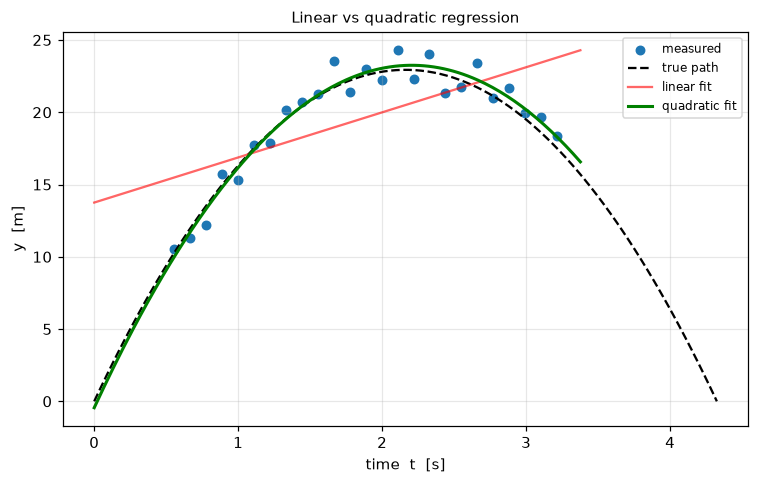

In [16]:
# TODO 3: สร้างเมทริกซ์ A2 (ขนาด m x 3 : คอลัมน์ 1, t, t^2) แล้วหา w2
A2 = np.column_stack((np.ones_like(t), t, t**2))
w2 = np.linalg.lstsq(A2, y, rcond=None)[0]

# ลองวิธี numpy  เพื่อแก้ปัญหา least squares
result2 = np.linalg.lstsq(A2, y, rcond=None)
print("ค่า w2 จาก numpy =", result2[0])

# ลองวิธี cvxpy  เพื่อแก้ปัญหา least squares
z2 = cvx.Variable(3)
objective2 = cvx.Minimize(cvx.sum_squares(A2 @ z2 - y))
prob2 = cvx.Problem(objective2)
prob2.solve()
print("ค่า w2 จาก cvxpy =", z2.value)

# -------------------- สามารถแก้ได้ตามอิสระ -------- #
rmse2 = np.sqrt(np.mean((A2 @ w2 - y) ** 2))
print(f"โมเดลพาราโบลา : y = {w2[0]:+.3f} {w2[1]:+.3f} t {w2[2]:+.3f} t^2")
print(f"RMSE บนข้อมูลที่วัดได้ = {rmse2:.4f}   (เส้นตรงได้ {rmse1:.4f})")

# เทียบกับเส้นทางจริง เพื่อดูว่าโมเดลไหนใกล้ความจริงกว่ากัน
pred1_true = w1[0] + w1[1] * t_true
pred2_true = w2[0] + w2[1] * t_true + w2[2] * t_true ** 2
print(f"\nเทียบกับเส้นทางจริง : RMSE เส้นตรง = {np.sqrt(np.mean((pred1_true - y_true) ** 2)):.3f}"
      f"   Polynomial Regression = {np.sqrt(np.mean((pred2_true - y_true) ** 2)):.3f}")

plt.figure(figsize=(7, 4.5))
plt.scatter(t, y, s=30, label="measured")
plt.plot(t_true, y_true, "k--", lw=1.5, label="true path")
plt.plot(ts, w1[0] + w1[1] * ts, "r-", lw=1.5, alpha=0.6, label="linear fit")
plt.plot(ts, w2[0] + w2[1] * ts + w2[2] * ts ** 2, "g-", lw=2, label="quadratic fit")
plt.xlabel("time  t  [s]"); plt.ylabel("y  [m]"); plt.legend(fontsize=8)
plt.title("Linear vs quadratic regression", fontsize=10)
plt.tight_layout()
plt.show()

---
## เสริม ดึงค่าออกจากสัมประสิทธิ์ (ไม่ต้องส่ง)

ทำไม regression ถึงมีประโยชน์กับงานวิศวกรรม **สัมประสิทธิ์ที่ fit ได้
มีความหมายทางกายภาพ**

เทียบสมการที่ fit ได้กับสมการทางฟิสิกส์ทีละพจน์

$$\underbrace{w_0 + w_1 t + w_2 t^2}_{\text{จาก regression}}
\quad\longleftrightarrow\quad
\underbrace{0 + (v_0\sin\theta)\, t - \tfrac{1}{2} g\, t^2}_{\text{จากฟิสิกส์}}$$



---
# Part 2 : กรองสัญญาณรบกวนด้วย Optimization

## โจทย์

สมมติว่าได้รับสัญญาณแบบ binary (0, 1) ที่ถูกรบกวนด้วย noise ระหว่างส่งผ่านช่องสื่อสาร
วัตถุประสงค์คือกู้คืนสัญญาณต้นฉบับโดยลด noise ให้ได้มากที่สุด

| ตัวแปร | ความหมาย |
|---|---|
| $x$ | สัญญาณไบนารีต้นฉบับ โดย $x \in \{0, 1\}$ |
| $\epsilon$ | noise |
| $y$ (หรือ `x_cor`) | สัญญาณที่รับได้ ซึ่งมี noise ปะปน |

ความสัมพันธ์คือ

$$y = x + \epsilon$$

เรารู้ล่วงหน้าว่าสัญญาณต้นฉบับ **เป็นค่าคงที่เป็นช่วง ๆ**
ดังนั้นข้อมูลตรงนี้คือสิ่งที่อ้างอิงสำหรับใช้แยก noise ออกจากสัญญาณ

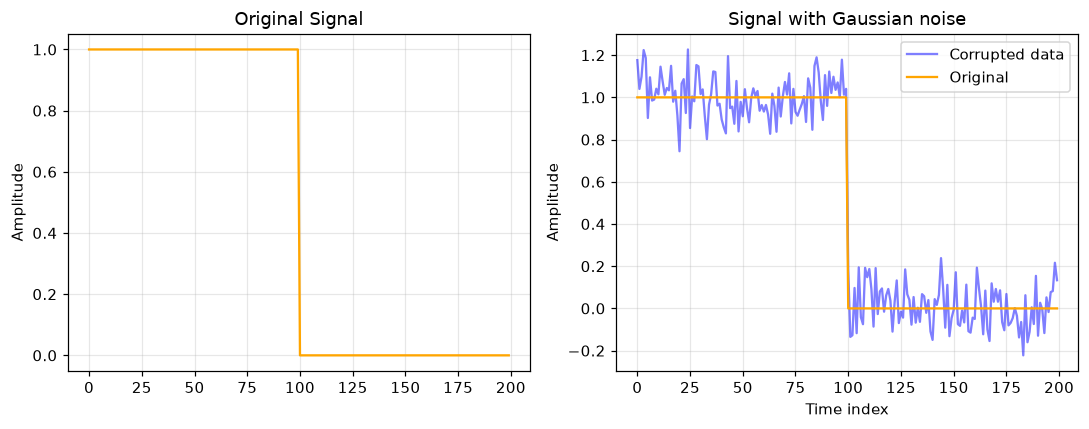

ความยาวสัญญาณ n = 200
ขนาดของ noise ทั้งก้อน ||noise||_2 = 1.448 


In [17]:
np.random.seed(0)

ts_first_phase = np.ones([100, 1])
ts_second_phase = np.zeros([100, 1])

x_sig = np.vstack([ts_first_phase, ts_second_phase])          # สัญญาณต้นฉบับ

noise = 0.1 * np.random.randn(len(x_sig), 1)
x_cor = x_sig + noise                                         # สัญญาณที่ถูกรบกวน

fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
ax[0].plot(x_sig, color="orange")
ax[0].set_title("Original Signal")
ax[0].set_ylabel("Amplitude")
ax[1].plot(x_cor, color="blue", alpha=0.5, label="Corrupted data")
ax[1].plot(x_sig, color="orange", label="Original")
ax[1].set_title("Signal with Gaussian noise")
ax[1].set_xlabel("Time index")
ax[1].set_ylabel("Amplitude")
plt.tight_layout()
plt.legend()
plt.show()

n = len(x_sig)
print(f"ความยาวสัญญาณ n = {n}")
print(f"ขนาดของ noise ทั้งก้อน ||noise||_2 = {float(np.linalg.norm(noise)):.3f} ")

---
## ข้อ 4 : กู้คืนสัญญาณด้วย $L_1$ optimization

### แนวคิด

เรานำวิธีการ L1 optimization มาประยุกต์ใช้เพื่อการกู้คืนสัญญาณ และช่วยลดสัญญาณรบกวน

optimization problem:

<br>

$$
\begin{align*}
\min \quad & \lVert Dx \rVert_1 \\
\text{subject to} \quad & \lVert x-x_{\text{cor}} \rVert_2 < \beta
\end{align*}
$$

<br>

จากนั้น ให้ทำการ plot สัญญาณที่กู้คืนมาได้ พร้อมทั้งทดลองปรับค่าของพารามิเตอร์ regularization parameter $ \beta $

- การปรับค่า $ \beta $ สำหรับ trade-off ระหว่าง data fidelity และ sparsity ของผลลัพธ์

- ถ้าเลือก $ \beta $ ที่มีค่ามากขึ้น จะทำให้มีการ regularization  ซึ่งอาจช่วยลดสัญญาณรบกวนได้ดีขึ้น แต่ก็เสี่ยงที่จะทำให้สูญเสียรายละเอียดเอกลักษณ์ของสัญญาณ

- ถ้าเลือก $ \beta $ ที่มีค่าน้อยลง จะลดการเน้น regularization ซึ่งช่วยเก็บรายละเอียดสัญญาณ แต่ก็อาจทำให้สัญญาณรบกวนยังคงอยู่ในผลลัพธ์

ตัวอย่างของสัญญาณที่กู้คืนด้วย $ \beta $ ที่เหมาะสมจะแสดงดังรูปใน cell ก่อนหน้านี้

Hint : "$L_2$ Norm with a Constraint" จากเอกสารหน้า 89 แต่อย่าลืมใช้เป็น $L_1$ Norm

(200,)
(199, 200) 1
beta = 1      status = optimal  ||x_rec - x_cor||_2 = 1.000
beta = 1.1    status = optimal  ||x_rec - x_cor||_2 = 1.100
beta = 1.2    status = optimal  ||x_rec - x_cor||_2 = 1.200
beta = 1.3    status = optimal  ||x_rec - x_cor||_2 = 1.300
beta = 1.4    status = optimal  ||x_rec - x_cor||_2 = 1.400
beta = 1.5    status = optimal  ||x_rec - x_cor||_2 = 1.500


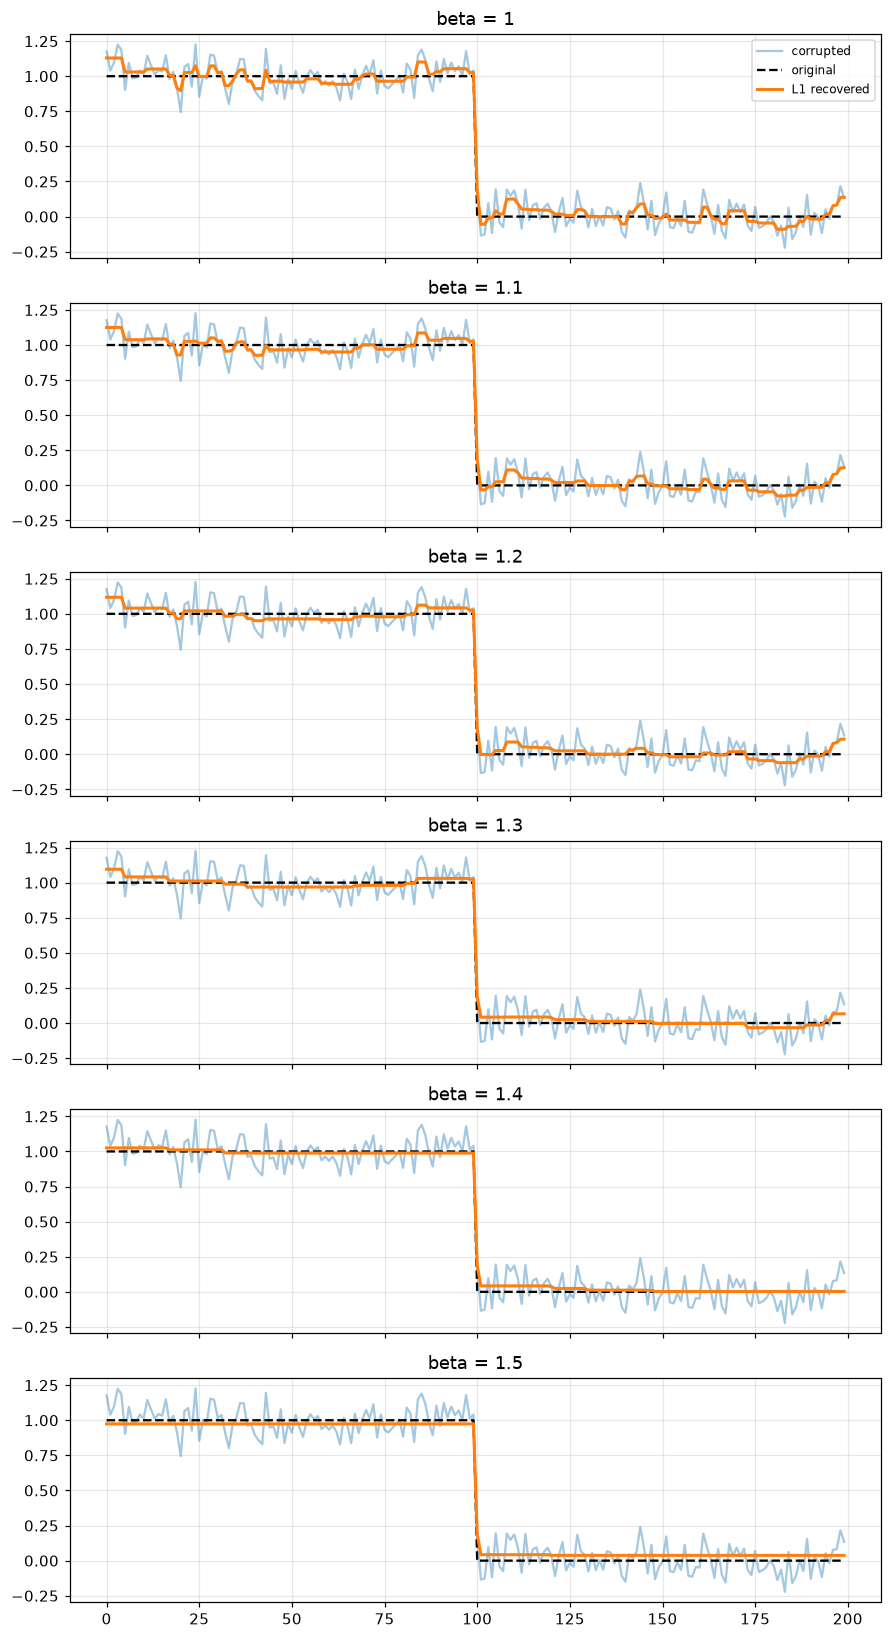

In [51]:
# TODO 4: กู้คืนสัญญาณด้วย L1 optimization แล้ว plot สัญญาณที่กู้คืนได้
#         พร้อมทดลองปรับค่า beta หลาย ๆ ค่า

y_obj = x_cor.flatten()
print(y_obj.shape)

D = np.eye(n) - np.eye(n, k=1)   # difference matrix
D = D[:n-1, :]  # Adjust D to be (n-1) x n
print(D.shape, np.count_nonzero(D @ x_sig.flatten()))

# beta = 1.5  # ปรับค่า beta เพื่อดูผลลัพธ์ที่แตกต่างกัน
# x = cvx.Variable(n)
# objective = cvx.Minimize(cvx.norm(D @ x, 1))                # min ||Dx||_1
# constraints = [cvx.norm(x - y_obj, 2) <= beta]              # s.t. ||x - x_cor||_2 <= beta
# prob = cvx.Problem(objective, constraints)
# prob.solve()

# print(f"status: {prob.status}, optimal value = {prob.value:.4f}")
# x_rec = x.value


betas = [1, 1.1, 1.2, 1.3, 1.4,1.5]
fig, axes = plt.subplots(len(betas), 1, figsize=(8, 2.5 * len(betas)), sharex=True)

for ax, beta in zip(axes, betas):
    x = cvx.Variable(n)
    objective = cvx.Minimize(cvx.norm(D @ x, 1))
    constraints = [cvx.norm(x - y_obj, 2) <= beta]
    prob = cvx.Problem(objective, constraints)
    prob.solve()
    x_rec = x.value
    print(f"beta = {beta:<6} status = {prob.status:<8} ||x_rec - x_cor||_2 = {np.linalg.norm(x_rec - y_obj):.3f}")

    ax.plot(y_obj, alpha=0.4, label="corrupted")
    ax.plot(x_sig, "k--", label="original")
    ax.plot(x_rec, lw=2, label="L1 recovered")
    ax.set_title(f"beta = {beta}")
axes[0].legend(fontsize=8)

plt.tight_layout(); plt.show()

---
## ข้อ 5  : ทำไมต้อง $L_1$ ไม่ใช่ $L_2$

โจทย์ข้อ 4 ใช้ $\lVert Dx \rVert_1$ เป็น objective คำถามคือถ้าเปลี่ยนเป็น
$\lVert Dx \rVert_2$ ล่ะ จะต่างกันอย่างไร

$$\min_x \lVert Dx \rVert_1 \quad\text{เทียบกับ}\quad \min_x \lVert Dx \rVert_2
\qquad \text{(constraint เหมือนกัน)}$$

**ข้อสำคัญ:** สามารถกลับไปดูในสไลด์ได้ความแตกต่างระหว่าง  $L_1$ และ $L_2$

- $L_2$ ลงโทษหนักมาก (ยกกำลังสอง) ดังนั้น "เฉลี่ยความเปลี่ยนแปลงให้ทุกจุดนิดหน่อย"
- $L_1$ ลงโทษตามขนาดตรง ๆ มันจึงยอมให้ **บางจุดกระโดดแรง** แลกกับให้จุดที่เหลือเป็นศูนย์สนิท

**โจทย์:** รันเทียบสองแบบที่ $\beta$ เดียวกัน แล้วดูว่าขอบของสัญญาณต่างกันอย่างไร

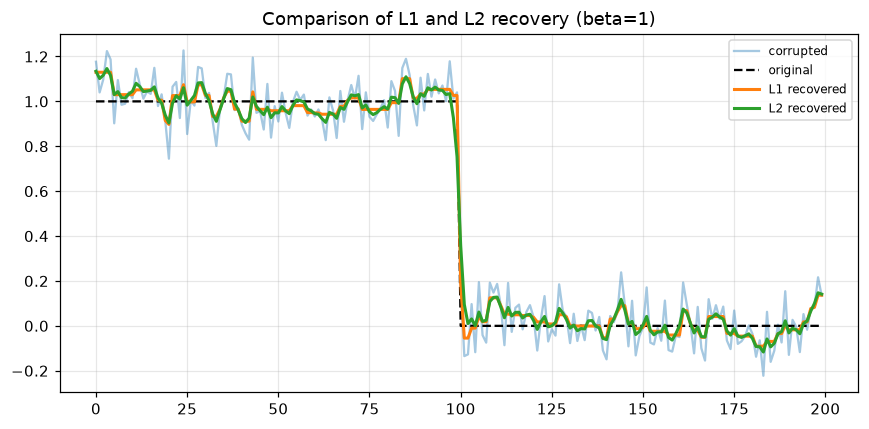

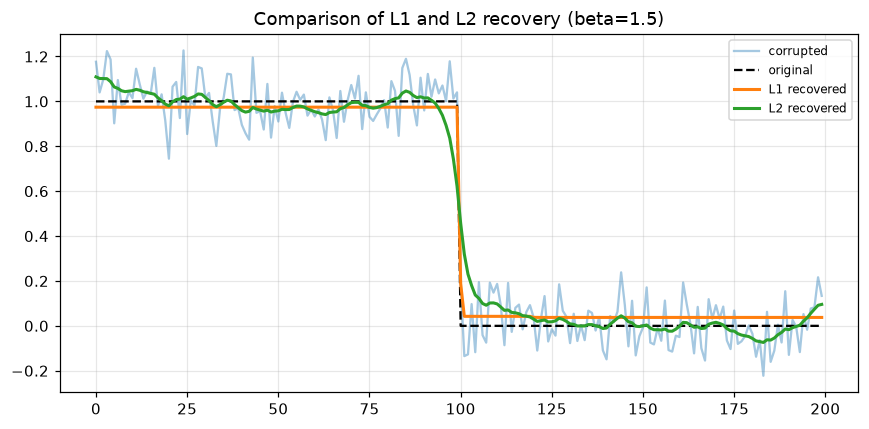

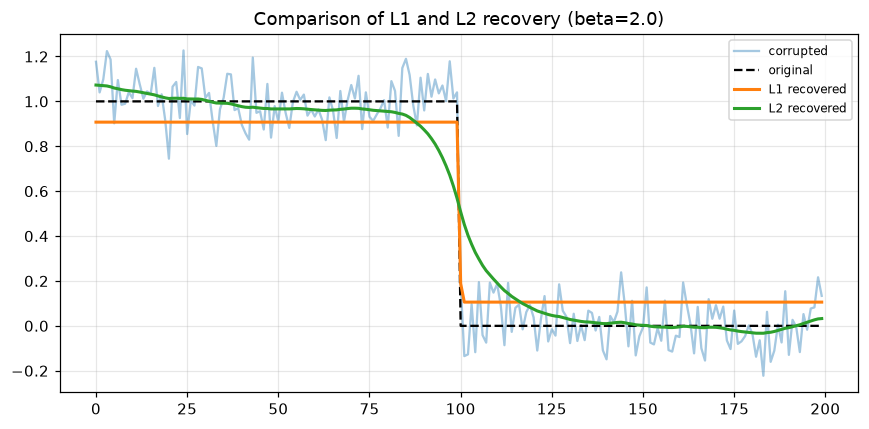

In [56]:
# TODO 5: แก้ปัญหาแบบ L1 และ L2 ที่ beta เดียวกัน แล้ว plot เทียบกัน
#         ดูว่าขอบของสัญญาณต่างกันอย่างไร

beta = [1, 1.5, 2.0]

for b in beta:
    x1 = cvx.Variable(n)
    objective1 = cvx.Minimize(cvx.norm(D @ x1, 1))
    constraints1 = [cvx.norm(x1 - y_obj, 2) <= b]
    prob1 = cvx.Problem(objective1, constraints1)
    prob1.solve()
    x_rec_L1 = x1.value

    x2 = cvx.Variable(n)
    objective2 = cvx.Minimize(cvx.norm(D @ x2, 2))
    constraints2 = [cvx.norm(x2 - y_obj, 2) <= b]
    prob2 = cvx.Problem(objective2, constraints2)
    prob2.solve()
    x_rec_L2 = x2.value

    plt.figure(figsize=(8, 4))
    plt.plot(y_obj, alpha=0.4, label="corrupted")
    plt.plot(x_sig, "k--", label="original")
    plt.plot(x_rec_L1, lw=2, label="L1 recovered")
    plt.plot(x_rec_L2, lw=2, label="L2 recovered")
    plt.title(f"Comparison of L1 and L2 recovery (beta={b})")
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

> **เขียนตอบข้อ 5 ตรงนี้** — ขอบของสัญญาณที่กู้คืนได้จาก $L_1$ และ $L_2$ ต่างกันอย่างไร เพราะอะไร

**สังเกต:** ที่ $\beta = 1.4$ เท่ากัน $L_1$ มีขอบที่คมกว่า ส่วน $L_2$ มีขอบที่มนกว่า ขอบของ $L_1$ คมเป็นขั้นบันได โดยลดจาก ≈0.99 ลงไปที่ ≈0.04 ภายใน 1–2 ช่อง ส่วนขอบของ $L_2$ ค่อย ๆ ลาดลงยาวหลายสิบช่อง (0.97 → 0.93 → 0.88 → 0.78 → 0.64 → …) นอกจากนี้ในช่วงที่สัญญาณควรแบน $L_1$ ก็แบนสนิทกว่า ขณะที่ $L_2$ ยังมีลูกคลื่นเล็ก ๆ เหลืออยู่

**เหตุผล:** objective $\lVert Dx\rVert$ ลงโทษขนาดของผลต่างระหว่างจุดที่อยู่ติดกัน ถ้าเทียบการลดค่าจาก 1 ไป 0 สองแบบ
L2 จะค่อยๆแบ่งเป็นก้าวเล็กๆ เพื่อให้สัญญาณค่อยๆเปลี่ยนแปลงเพราะมีต้นทุนถูกว่าจึงให้สัญญาณขอบมนกว่า  L1 จะเปลี่ยนได้ทันทีเพราะต้นทุนเท่าเดิมเสมอ

---
## สรุปสิ่งที่ต้องส่ง

| ข้อ | ต้องมี |
|---|---|
| 1 | โค้ด TODO 1 + กราฟ 2 แผง + ตอบว่าควรใช้สมการ order เท่าไร เพราะอะไร |
| 2 | โค้ด TODO 2 (สร้าง $A$ และหา $w^\star$) + กราฟ linear fit |
| 3 | โค้ด TODO 3 (สร้าง $A$ แบบ 3 คอลัมน์ และหา $w^\star$) + กราฟเทียบ linear กับ quadratic |
| เสริม | ดึงค่าออกจากสัมประสิทธิ์ **ไม่ต้องส่ง** |
| 4 | โค้ด $L_1$ optimization + กราฟสัญญาณที่กู้คืนได้ เมื่อปรับ $\beta$ หลายค่า |
| 5 | โค้ดเทียบ $L_1$ กับ $L_2$ ที่ $\beta$ เดียวกัน + กราฟเทียบ + อธิบายว่าขอบของสัญญาณต่างกันอย่างไร |
